# Machine Learning Project: Hospital Readmission Prediction

## 1. Problem Framing
* **Stakeholder:** Hospital Care-Planning Team and Administrators.
* **Decision Need:** Identifying which diabetic patients require immediate extra follow-up care and resource allocation after discharge to prevent early readmission.
* **Primary Lens:** 30-day hospital readmission risk prediction.
* **Secondary Lens:** High-risk patient profiling (identifying common characteristics and risk drivers).
* **Unit of Analysis:** One single hospital encounter (visit) by a diabetic patient.
* **Exact Task/Output:** Supervised Binary Classification to predict early hospital readmission risk:
  * **Positive Class (1):** Patient readmitted within 30 days (`<30`)
  * **Negative Class (0):** Patient not readmitted within 30 days (`NO` or `>30` combined)
* **Rationale:** Aligns directly with the clinical decision need and the US Centers for Medicare & Medicaid Services (CMS) Hospital Readmissions Reduction Program (HRRP). Hospitals are evaluated and penalized specifically on 30-day bounce-backs; distinguishing between late readmission (>30 days) and no readmission is clinically irrelevant for acute transitional discharge planning.



# Preprocessing

## Problem Formulation: Acute 30-Day Hospital Readmission

In alignment with the CMS Hospital Readmissions Reduction Program (HRRP), this pipeline predicts whether a diabetic inpatient requires acute post-discharge intervention to prevent return within 30 days. Combining `NO` and `>30` into a single Negative class (`0`) eliminates non-actionable clinical ambiguity between long-term chronic bounce-backs and non-returns, focusing model capacity strictly on acute early deterioration signals while maintaining strict patient-stratified empirical hygiene.


In [1]:
import os
import sys
import math
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Ensure working directory is project root for relative paths
if not os.path.exists('dataset_extracted') and os.path.exists('../dataset_extracted'):
    os.chdir('..')

data_dir = 'dataset_extracted' if os.path.exists('dataset_extracted') else '../dataset_extracted'
plots_dir = 'plots' if os.path.exists('plots') else 'preprocessing/plots'
# Save outputs directly to dataset_processed so all models in models/ and binary_classification/ find them
processed_dir = 'dataset_processed'

warnings.filterwarnings('ignore')
%matplotlib inline
sns.set_theme(style="whitegrid")

os.makedirs(f'{plots_dir}/Preprocessing', exist_ok=True)
os.makedirs(processed_dir, exist_ok=True)


In [2]:
# Load initial dataset
df = pd.read_csv(f'{data_dir}/diabetic_data.csv', keep_default_na=False)

# Parse IDS_mapping.csv (3 tables stacked, blank-row separated)
with open(f'{data_dir}/IDS_mapping.csv', 'r') as f:
    lines = f.readlines()

mapping_dicts, current_map = {}, None
for line in lines:
    line = line.strip()
    if not line or line.strip(',') == '':
        continue
    if line.endswith('_id,description'):
        current_map = line.split(',')[0]
        mapping_dicts[current_map] = {}
    elif current_map:
        key, val = line.split(',', 1)
        mapping_dicts[current_map][int(key)] = val.strip().strip('"')

# Map descriptor columns for discharge/admission
code_cols = ['admission_type_id', 'discharge_disposition_id', 'admission_source_id']
for c in code_cols:
    new = c.replace('_id', '_desc')
    df[new] = df[c].map(mapping_dicts[c]).fillna('Unknown/Unmapped')

print(f"Initial dataset loaded: {df.shape}")


Initial dataset loaded: (101766, 53)


## Preprocessing Step 1 · Load Data & Understand Its Structure
We confirm the dataset shape, column types, and data presence one final time before applying transformations.

> **Note:** Missing value placeholders (e.g. `'?'`, `'Unknown/Invalid'`) are still stored as raw string tokens at this ingestion stage, which is why standard `isnull()` counts initially show 0.


In [3]:
print(f"Dataset shape before any preprocessing: {df.shape}")
print(f"Columns: {df.columns.tolist()}")
print("\nData types:")
print(df.dtypes.value_counts())
print("\nNull counts (top 10):")
print(df.isnull().sum().sort_values(ascending=False).head(10))



Dataset shape before any preprocessing: (101766, 53)
Columns: ['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted', 'admission_type_desc', 'discharge_disposition_desc', 'admission_source_desc']

Data types:
object    40
int64     13
Nam

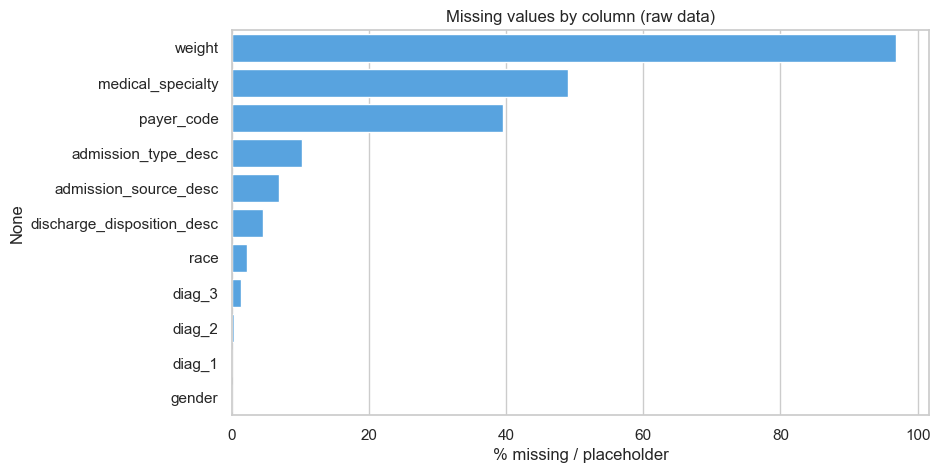

In [4]:
# Plot A: Missing values and placeholder strings per column in raw data
ph = ['?', 'Unknown/Invalid', 'Not Available', 'NULL', 'Not Mapped']
miss = (df.isin(ph).mean() * 100).sort_values(ascending=False)
miss = miss[miss > 0]
plt.figure(figsize=(9, 5))
sns.barplot(x=miss.values, y=miss.index, color='#42a5f5')
plt.xlabel('% missing / placeholder')
plt.title('Missing values by column (raw data)')
plt.savefig(f'{plots_dir}/Preprocessing/missing_values.png', bbox_inches='tight')
plt.show()


## Preprocessing Step 2 · Remove Unjustified Duplicate Records (Sanity Check)
We check for exact duplicate rows. Keeping duplicate records would artificially inflate confidence on repeated encounter profiles.


In [5]:
before = len(df)
df_clean = df.drop_duplicates().copy()
after = len(df_clean)
print(f"Rows before: {before} | Rows after dropping duplicates: {after} | Removed: {before - after}")



Rows before: 101766 | Rows after dropping duplicates: 101766 | Removed: 0


## Preprocessing Step 3 · Handle Missing Values & Remove Terminal Encounters
Missing values are parsed from placeholder strings (`?`, `Unknown/Invalid`) and hidden numeric administrative nulls. Informative clinical missingness (`medical_specialty`, `payer_code`) is preserved as `"Unknown"`, while test absences are mapped to `"Not tested"`. Terminal encounters (Hospice/Expired disposition codes 11, 13, 14, 19, 20, 21) are removed to eliminate target leakage, as deceased patients cannot physically be readmitted.


Removed terminal patients: 2423 (101766 -> 99343)
Shape after removing terminal patients: (99343, 53)


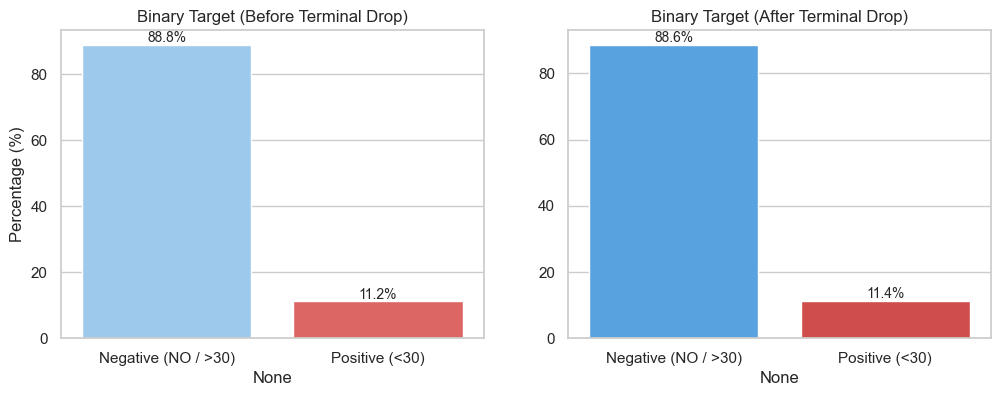

In [6]:
import numpy as np

# Step 3a: Replace placeholder strings with NaN
placeholders = ['?', 'Unknown/Invalid', 'Not Available', 'NULL', 'Not Mapped']
df_clean.replace(placeholders, np.nan, inplace=True)

# Step 3b: Drop Hospice / Deceased patients (conceptual leakage — they cannot be readmitted)
rows_before_terminal = len(df_clean)
terminal_codes = [11, 13, 14, 19, 20, 21]
df_clean = df_clean[~df_clean['discharge_disposition_id'].isin(terminal_codes)].copy()
terminal_dropped = rows_before_terminal - len(df_clean)
print(f"Removed terminal patients: {terminal_dropped} ({rows_before_terminal} -> {len(df_clean)})")
print(f"Shape after removing terminal patients: {df_clean.shape}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# Binary view: Positive (<30) vs Negative (NO + >30)
bin_dist_before = pd.Series({
    'Negative (NO / >30)': (df['readmitted'] != '<30').mean() * 100,
    'Positive (<30)': (df['readmitted'] == '<30').mean() * 100
})
bin_dist_after = pd.Series({
    'Negative (NO / >30)': (df_clean['readmitted'] != '<30').mean() * 100,
    'Positive (<30)': (df_clean['readmitted'] == '<30').mean() * 100
})
sns.barplot(x=bin_dist_before.index, y=bin_dist_before.values, ax=axes[0], palette=['#90caf9', '#ef5350'])
for c_bar in axes[0].containers: axes[0].bar_label(c_bar, fmt='%.1f%%', fontsize=10)
axes[0].set_title("Binary Target (Before Terminal Drop)")
axes[0].set_ylabel("Percentage (%)")
sns.barplot(x=bin_dist_after.index, y=bin_dist_after.values, ax=axes[1], palette=['#42a5f5', '#e53935'])
for c_bar in axes[1].containers: axes[1].bar_label(c_bar, fmt='%.1f%%', fontsize=10)
axes[1].set_title("Binary Target (After Terminal Drop)")
plt.savefig(f'{plots_dir}/Preprocessing/phase1_terminal_drop.png', bbox_inches='tight')
plt.show()


In [7]:
# Step 3c: Convert hidden null IDs to NaN before imputation
null_id_codes = {
    'admission_type_id': [5, 6, 8],
    'discharge_disposition_id': [18, 25, 26],
    'admission_source_id': [9, 15, 17, 20, 21]
}
for col, ids in null_id_codes.items():
    df_clean[col] = df_clean[col].replace(ids, np.nan)

# Step 3d: Impute informative missing values — missingness itself carries signal
informative_cols = ['medical_specialty', 'payer_code', 'race',
                    'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
                    'admission_type_desc', 'discharge_disposition_desc', 'admission_source_desc']
for col in informative_cols:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].fillna('Unknown')

# Step 3e: Impute test results — "None" means "Not tested", which is a valid clinical signal
test_cols = ['max_glu_serum', 'A1Cresult']
for col in test_cols:
    df_clean[col] = df_clean[col].replace('None', 'Not tested').fillna('Not tested')

# Step 3f: Drop a tiny fraction of rows with missing critical fields (gender, primary diagnosis)
rows_before = len(df_clean)
df_clean.dropna(subset=['gender', 'diag_1', 'diag_2', 'diag_3'], inplace=True)
dropped_critical = rows_before - len(df_clean)
pct_critical = (dropped_critical / rows_before) * 100
print(f"Rows dropped with missing critical fields (gender/diag): {dropped_critical} ({pct_critical:.1f}%)")

print(f"\nShape after full missing value handling: {df_clean.shape}")
print("\nRemaining nulls:")
remaining = df_clean.isnull().sum()
print(remaining[remaining > 0] if remaining.sum() > 0 else "None — dataset is clean!")


Rows dropped with missing critical fields (gender/diag): 1521 (1.5%)

Shape after full missing value handling: (97822, 53)

Remaining nulls:
weight    94723
dtype: int64


## Preprocessing Step 4 · Fix Data Types
ID code columns are cast from `int64` to `object` (categorical) so models never treat administrative codes as numeric magnitudes. Count features (`count_feats`) are established as our unified numerical count list.


In [8]:
# ID code columns should be categorical (not numeric)
code_cols = ['admission_type_id', 'discharge_disposition_id', 'admission_source_id']
for col in code_cols:
    df_clean[col] = df_clean[col].astype(str)

# Unified list of numerical count features defined once
count_feats = ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications',
               'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']

print("Data types after fixing:")
print(df_clean.dtypes.value_counts())
print("\nSample dtypes:")
print(df_clean[code_cols + count_feats].dtypes)


Data types after fixing:
object    43
int64     10
Name: count, dtype: int64

Sample dtypes:


admission_type_id           object
discharge_disposition_id    object
admission_source_id         object
time_in_hospital             int64
num_lab_procedures           int64
num_procedures               int64
num_medications              int64
number_outpatient            int64
number_emergency             int64
number_inpatient             int64
number_diagnoses             int64
dtype: object


## Preprocessing Step 5 · Validity Checks
We confirm that only valid gender categories exist and verify that no medical count features contain negative values.


In [9]:
# Check for 'Unknown/Invalid' gender — filter out non-binary values (non-imputable)
invalid_gender = df_clean[~df_clean['gender'].isin(['Male', 'Female'])]
print(f"Rows with invalid gender values: {len(invalid_gender)}")
df_clean = df_clean[df_clean['gender'].isin(['Male', 'Female'])].copy()

# Verify count columns have no negative values (invalid clinical counts)
for col in count_feats:
    neg = (df_clean[col] < 0).sum()
    if neg > 0:
        print(f"WARNING: {col} has {neg} negative values — clipping to 0")
        df_clean[col] = df_clean[col].clip(lower=0)

print(f"\nFinal valid gender distribution:")
print(df_clean['gender'].value_counts())
print(f"\nShape after consistency checks: {df_clean.shape}")


Rows with invalid gender values: 0

Final valid gender distribution:
gender
Female    52670
Male      45152
Name: count, dtype: int64

Shape after consistency checks: (97822, 53)


## Preprocessing Step 6 · Transform Columns — Standardize Representations
We drop redundant `_desc` columns to prevent duplicate representation of admission/discharge codes, and standardize `change` (`changed/unchanged`) and `diabetesMed` (`yes/no`) casing.


In [10]:
# Drop the redundant _desc columns — they are exact text equivalents of _id columns
# which will be properly grouped and encoded in Feature Engineering. Keeping them
# would cause double-representation of the same information.
desc_cols_to_drop = ['admission_type_desc', 'discharge_disposition_desc', 'admission_source_desc']
df_clean.drop(columns=desc_cols_to_drop, errors='ignore', inplace=True)
print(f"Dropped redundant descriptor columns: {desc_cols_to_drop}")

# Standardize the 'change' and 'diabetesMed' columns to lowercase for consistency
if 'change' in df_clean.columns:
    df_clean['change'] = df_clean['change'].str.lower().replace({'ch': 'changed', 'no': 'unchanged'})
if 'diabetesMed' in df_clean.columns:
    df_clean['diabetesMed'] = df_clean['diabetesMed'].str.lower()

print(f"\n'change' distribution: {df_clean['change'].value_counts().to_dict()}")
print(f"'diabetesMed' distribution: {df_clean['diabetesMed'].value_counts().to_dict()}")
print(f"\nShape after column transforms: {df_clean.shape}")



Dropped redundant descriptor columns: ['admission_type_desc', 'discharge_disposition_desc', 'admission_source_desc']

'change' distribution: {'unchanged': 52360, 'changed': 45462}
'diabetesMed' distribution: {'yes': 75511, 'no': 22311}

Shape after column transforms: (97822, 50)


## Preprocessing Step 7 · Remove Irrelevant Columns & Prevent Target Leakage
We drop identifiers (`encounter_id`), uninformative constants (`weight`, `examide`, `citoglipton`), and near-zero variance medications (>99% 'No') that provide no predictive signal.


In [11]:
# Drop identifier and constant columns
cols_to_drop = ['weight', 'examide', 'citoglipton', 'encounter_id']
df_clean.drop(columns=cols_to_drop, errors='ignore', inplace=True)
print(f"Dropped identifier / constant columns: {[c for c in cols_to_drop if c not in df_clean.columns]}")

# Dynamically detect and drop near-zero variance medications (>99% 'No')
all_med_cols = ['metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride',
                'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone',
                'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'insulin',
                'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone',
                'metformin-rosiglitazone', 'metformin-pioglitazone']

dropped_meds = [m for m in all_med_cols if m in df_clean.columns and (df_clean[m] == 'No').mean() > 0.99]
df_clean.drop(columns=dropped_meds, errors='ignore', inplace=True)
print(f"\nDropped {len(dropped_meds)} near-zero variance medications: {dropped_meds}")
print(f"\nFinal shape after column removal: {df_clean.shape}")


Dropped identifier / constant columns: ['weight', 'examide', 'citoglipton', 'encounter_id']



Dropped 13 near-zero variance medications: ['nateglinide', 'chlorpropamide', 'acetohexamide', 'tolbutamide', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']

Final shape after column removal: (97822, 33)


## Preprocessing Step 8 · Investigate & Handle Outliers
Utilization count features exhibit extreme positive skew. High-utilizer patients represent the exact high-risk cohort of interest, so we deliberately retain these records and apply `log1p` scaling in the modeling pipeline.


In [12]:
# Revisit numerical count columns for outlier review
outlier_feats = [c for c in count_feats if c in df_clean.columns]

outlier_report = []
for col in outlier_feats:
    Q1, Q3 = df_clean[col].quantile(0.25), df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n_outliers = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
    outlier_report.append({'Feature': col, 'Q1': Q1, 'Q3': Q3, 'Upper Fence': upper, 'N Outliers': n_outliers, '% of Data': round(n_outliers / len(df_clean) * 100, 2)})

import pandas as pd
outlier_df = pd.DataFrame(outlier_report)
print("Outlier Summary (IQR method):")
from IPython.display import display
display(outlier_df)


Outlier Summary (IQR method):

,Feature,Q1,Q3,Upper Fence,N Outliers,% of Data
0,time_in_hospital,2.0,6.0,12.0,2141,2.19
1,num_lab_procedures,31.0,57.0,96.0,120,0.12
2,num_procedures,0.0,2.0,5.0,4787,4.89
3,num_medications,11.0,20.0,33.5,3253,3.33
4,number_outpatient,0.0,0.0,0.0,16222,16.58
5,number_emergency,0.0,0.0,0.0,10997,11.24
6,number_inpatient,0.0,1.0,2.5,6753,6.90
7,number_diagnoses,6.0,9.0,13.5,58,0.06


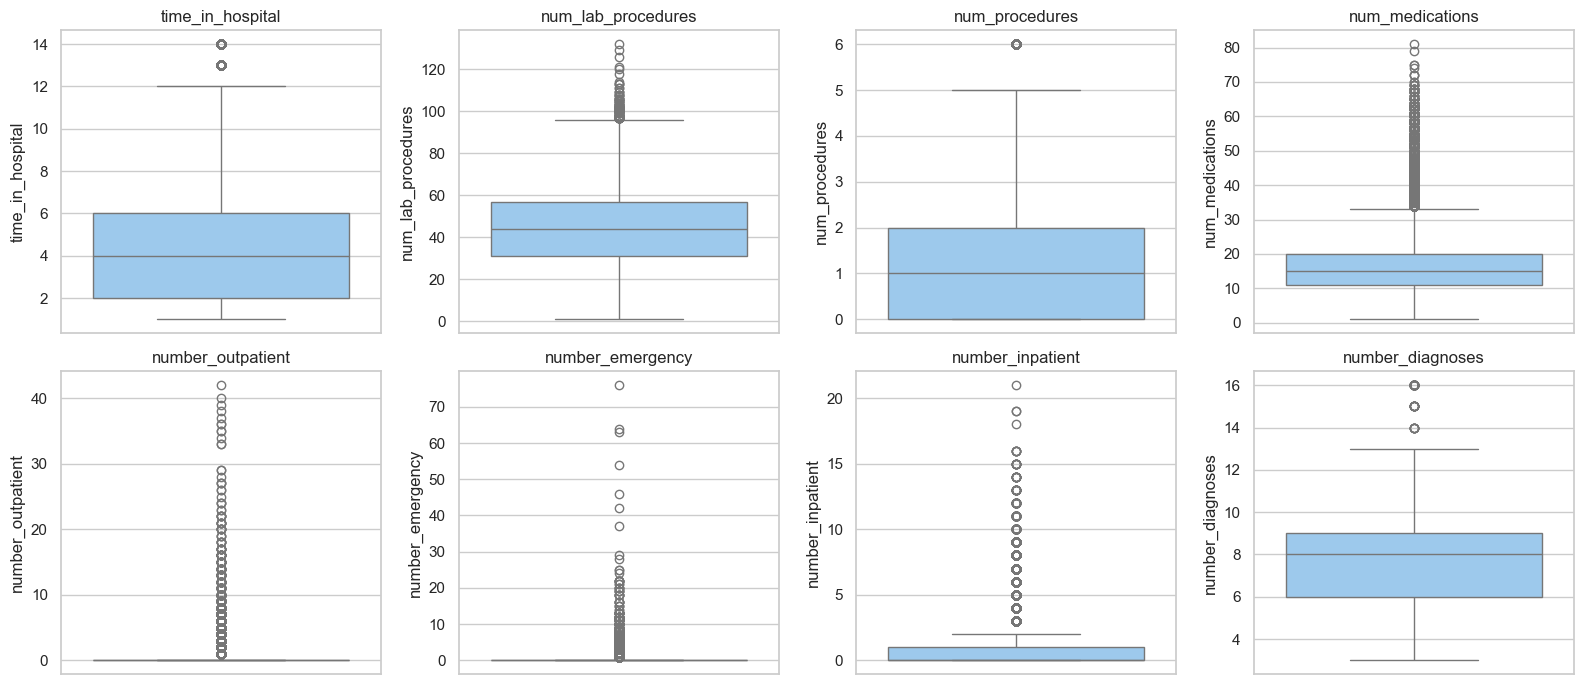

In [13]:
# Plot B: Boxplots of count_feats from df_clean (read-only)
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c_col in zip(axes.ravel(), count_feats):
    sns.boxplot(y=df_clean[c_col], ax=ax, color='#90caf9')
    ax.set_title(c_col)
plt.tight_layout()
plt.savefig(f'{plots_dir}/Preprocessing/outlier_boxplots.png', bbox_inches='tight')
plt.show()


## Preprocessing Step 9 · Split the Dataset by Patient ID
We split strictly on `patient_nbr` (80% train / 20% test) to prevent repeat patient visits from leaking into the test set. Stratification is based on each patient's initial visit readmission status.


Train set: (78331, 33) | Test set: (19491, 33)
Train patients: 55108 | Test patients: 13777
Patient overlap between train and test: 0 (must be 0)


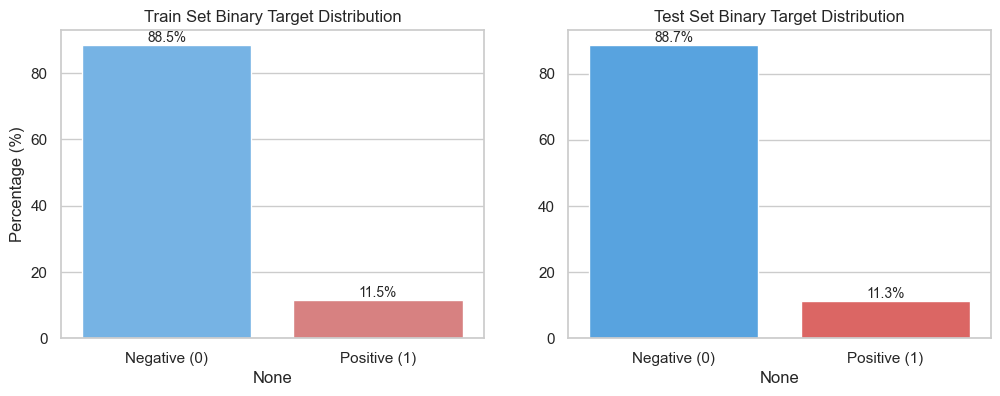

In [14]:
from sklearn.model_selection import train_test_split

# Define binary target for stratification: 1 if <30, else 0
first_encounters = df_clean.sort_values('patient_nbr').groupby('patient_nbr').first()
patient_targets = (first_encounters['readmitted'] == '<30').astype(int)

train_patients, test_patients = train_test_split(
    patient_targets.index,
    test_size=0.20,
    random_state=42,
    stratify=patient_targets
)

train_df = df_clean[df_clean['patient_nbr'].isin(train_patients)].copy()
test_df  = df_clean[df_clean['patient_nbr'].isin(test_patients)].copy()

print(f"Train set: {train_df.shape} | Test set: {test_df.shape}")
print(f"Train patients: {train_df['patient_nbr'].nunique()} | Test patients: {test_df['patient_nbr'].nunique()}")

# Verify no patient overlap
overlap = set(train_df['patient_nbr']) & set(test_df['patient_nbr'])
print(f"Patient overlap between train and test: {len(overlap)} (must be 0)")

train_bin_dist = pd.Series({
    'Negative (0)': (train_df['readmitted'] != '<30').mean() * 100,
    'Positive (1)': (train_df['readmitted'] == '<30').mean() * 100
})
test_bin_dist = pd.Series({
    'Negative (0)': (test_df['readmitted'] != '<30').mean() * 100,
    'Positive (1)': (test_df['readmitted'] == '<30').mean() * 100
})

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x=train_bin_dist.index, y=train_bin_dist.values, ax=axes[0], palette=['#64b5f6', '#e57373'])
for c in axes[0].containers: axes[0].bar_label(c, fmt='%.1f%%', fontsize=10)
axes[0].set_title("Train Set Binary Target Distribution")
axes[0].set_ylabel("Percentage (%)")
sns.barplot(x=test_bin_dist.index, y=test_bin_dist.values, ax=axes[1], palette=['#42a5f5', '#ef5350'])
for c in axes[1].containers: axes[1].bar_label(c, fmt='%.1f%%', fontsize=10)
axes[1].set_title("Test Set Binary Target Distribution")
plt.savefig(f'{plots_dir}/Preprocessing/phase2_split_stratification.png', bbox_inches='tight')
plt.show()



# Feature Engineering

All feature engineering below is designed around two core principles:
1. **Train-only learning**: Any mapping derived from the data (top-N categories, etc.) is computed from `train_df` only and applied to `test_df`.
2. **Clinical meaningfulness**: Features are created with domain knowledge, not just mathematical convenience.


## Feature Engineering Step 1 · Feature Creation
We create `total_visits` (inpatient + emergency + outpatient), `num_drug_changes` (care volatility), and `num_active_drugs` (polypharmacy load).


In [15]:
# 1a. Total prior visits (captures overall healthcare utilization intensity)
train_df['total_visits'] = train_df['number_outpatient'] + train_df['number_emergency'] + train_df['number_inpatient']
test_df['total_visits']  = test_df['number_outpatient']  + test_df['number_emergency']  + test_df['number_inpatient']

# 1b. Drug change intensity (how many medications were adjusted this visit)
drug_cols_present = [c for c in train_df.columns if c in
    ['metformin','repaglinide','nateglinide','chlorpropamide','glimepiride','acetohexamide',
     'glipizide','glyburide','tolbutamide','pioglitazone','rosiglitazone','acarbose','miglitol',
     'troglitazone','tolazamide','insulin','glyburide-metformin','glipizide-metformin',
     'glimepiride-pioglitazone','metformin-rosiglitazone','metformin-pioglitazone']]

def count_drug_changes(row): return sum(1 for d in drug_cols_present if row[d] in ['Up', 'Down'])
def count_active_drugs(row): return sum(1 for d in drug_cols_present if row[d] in ['Up', 'Down', 'Steady'])

train_df['num_drug_changes'] = train_df.apply(count_drug_changes, axis=1)
test_df['num_drug_changes']  = test_df.apply(count_drug_changes, axis=1)

train_df['num_active_drugs'] = train_df.apply(count_active_drugs, axis=1)
test_df['num_active_drugs']  = test_df.apply(count_active_drugs, axis=1)

print("New features created: total_visits, num_drug_changes, num_active_drugs")
print(train_df[['total_visits', 'num_drug_changes', 'num_active_drugs']].describe())



New features created: total_visits, num_drug_changes, num_active_drugs
       total_visits  num_drug_changes  num_active_drugs
count  78331.000000      78331.000000      78331.000000
mean       1.216926          0.286451          1.167520
std        2.334156          0.487434          0.912037
min        0.000000          0.000000          0.000000
25%        0.000000          0.000000          1.000000
50%        0.000000          0.000000          1.000000
75%        2.000000          1.000000          2.000000
max       80.000000          4.000000          5.000000


## Feature Engineering Step 2 · Feature Transformation Preview
Count features exhibit right-skew; `log1p` stabilizes variance while handling zeros cleanly. The transformation is formally applied inside the pipeline.


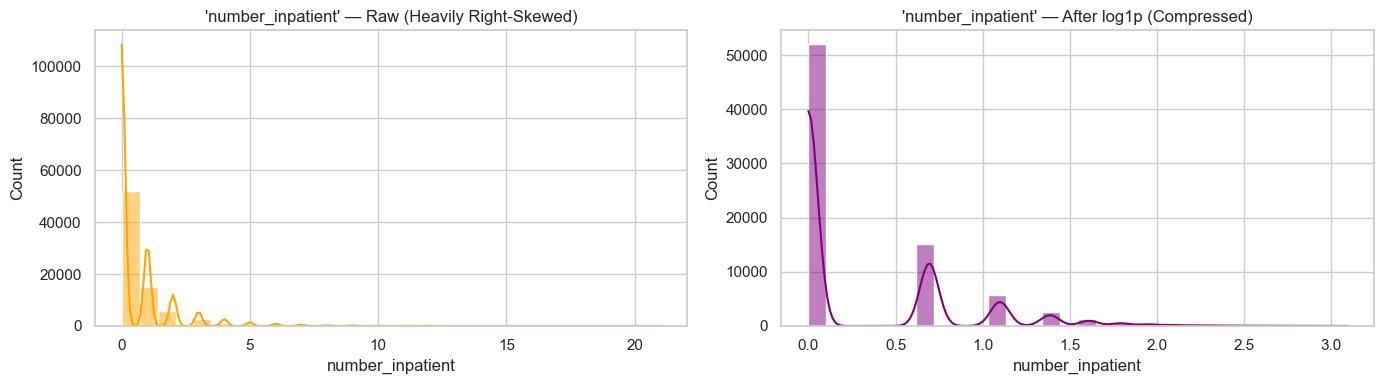

Log1p transformation will be applied inside the ColumnTransformer pipeline to all numeric features.
This ensures no leakage: the same log1p is a fixed mathematical function, not data-dependent.


In [16]:
# Visualize the transformation effect on the most skewed feature
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(train_df['number_inpatient'], bins=30, ax=axes[0], color='orange', kde=True)
axes[0].set_title("'number_inpatient' — Raw (Heavily Right-Skewed)")

sns.histplot(np.log1p(train_df['number_inpatient']), bins=30, ax=axes[1], color='purple', kde=True)
axes[1].set_title("'number_inpatient' — After log1p (Compressed)")

plt.tight_layout()
plt.savefig(f'{plots_dir}/Preprocessing/fe_log1p_preview.png', bbox_inches='tight')
plt.show()

print("Log1p transformation will be applied inside the ColumnTransformer pipeline to all numeric features.")
print("This ensures no leakage: the same log1p is a fixed mathematical function, not data-dependent.")



## Feature Engineering Step 3 · Feature Extraction (ICD-9 Diagnoses)
We map 700+ raw ICD-9 diagnosis codes (`diag_1`, `diag_2`, `diag_3`) into 9 clinical categories (`Diabetes`, `Circulatory`, `Respiratory`, etc.).


In [17]:
import re

def map_diagnosis(code):
    if pd.isna(code) or str(code) in ['?', 'nan']: return 'Other'
    if str(code).startswith('V') or str(code).startswith('E'): return 'Other'
    try:
        c = float(code)
        if c == 250: return 'Diabetes'
        if 390 <= c <= 459 or c == 785: return 'Circulatory'
        if 460 <= c <= 519 or c == 786: return 'Respiratory'
        if 520 <= c <= 579 or c == 787: return 'Digestive'
        if 800 <= c <= 999: return 'Injury'
        if 710 <= c <= 739: return 'Musculoskeletal'
        if 580 <= c <= 629 or c == 788: return 'Genitourinary'
        if 140 <= c <= 239: return 'Neoplasms'
        return 'Other'
    except: return 'Other'

for col in ['diag_1', 'diag_2', 'diag_3']:
    train_df[col] = train_df[col].apply(map_diagnosis)
    test_df[col]  = test_df[col].apply(map_diagnosis)

print("Diagnosis extraction complete. Unique categories (diag_1):")
print(train_df['diag_1'].value_counts())



Diagnosis extraction complete. Unique categories (diag_1):
diag_1
Circulatory        23730
Other              20426
Respiratory        10950
Digestive           7363
Injury              5343
Genitourinary       4011
Musculoskeletal     3884
Neoplasms           2460
Diabetes             164
Name: count, dtype: int64


## Feature Engineering Step 4 · Feature Combination (Intensity Ratios)
We construct `meds_per_day` and `lab_tests_per_day` to isolate clinical intensity from stay duration.


In [18]:
# Medications per day of hospital stay (treatment intensity)
train_df['meds_per_day'] = train_df['num_medications'] / np.maximum(1, train_df['time_in_hospital'])
test_df['meds_per_day']  = test_df['num_medications']  / np.maximum(1, test_df['time_in_hospital'])

# Lab tests per day of hospital stay (diagnostic intensity)
train_df['lab_tests_per_day'] = train_df['num_lab_procedures'] / np.maximum(1, train_df['time_in_hospital'])
test_df['lab_tests_per_day']  = test_df['num_lab_procedures']  / np.maximum(1, test_df['time_in_hospital'])

print("Combined rate features created: meds_per_day, lab_tests_per_day")
print(train_df[['meds_per_day', 'lab_tests_per_day']].describe())



Combined rate features created: meds_per_day, lab_tests_per_day
       meds_per_day  lab_tests_per_day
count  78331.000000       78331.000000
mean       5.079194          14.258850
std        3.810568          11.852748
min        0.125000           0.071429
25%        2.600000           6.500000
50%        4.000000          10.857143
75%        6.200000          18.000000
max       42.000000          92.000000


## Feature Engineering Step 5 · Feature Selection
We drop individual drug columns (captured via polypharmacy aggregates, keeping `insulin`) and `patient_nbr` (identifier).


In [19]:
# Drop raw drug columns — we've summarized them into num_drug_changes and num_active_drugs
drugs_to_drop = [d for d in drug_cols_present if d != 'insulin']  # Keep insulin — strongest single-drug predictor
train_df.drop(columns=drugs_to_drop, errors='ignore', inplace=True)
test_df.drop(columns=drugs_to_drop, errors='ignore', inplace=True)
print(f"Dropped {len(drugs_to_drop)} individual drug columns (summarized into aggregate features)")

# Drop patient_nbr — identifier, not a feature
for df_ in [train_df, test_df]:
    df_.drop(columns=['patient_nbr'], errors='ignore', inplace=True)

print(f"\nTrain shape after feature selection: {train_df.shape}")
print(f"Test shape after feature selection:  {test_df.shape}")
print(f"\nRemaining columns:")
print(train_df.columns.tolist())



Dropped 7 individual drug columns (summarized into aggregate features)

Train shape after feature selection: (78331, 30)
Test shape after feature selection:  (19491, 30)

Remaining columns:
['race', 'gender', 'age', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'insulin', 'change', 'diabetesMed', 'readmitted', 'total_visits', 'num_drug_changes', 'num_active_drugs', 'meds_per_day', 'lab_tests_per_day']


## Feature Engineering Step 6 · Feature Representation Refinement
We group long-tail specialties and payer codes into `Other`, map administrative codes into semantic clusters, and encode `age` ordinally (0–9).


In [20]:
# 6a. Group rare medical specialties — top 10 from TRAIN applied to both
top_specialties = train_df['medical_specialty'].value_counts().nlargest(10).index
train_df['medical_specialty'] = train_df['medical_specialty'].apply(lambda x: x if x in top_specialties else 'Other')
test_df['medical_specialty']  = test_df['medical_specialty'].apply(lambda x: x if x in top_specialties else 'Other')

# 6b. Group rare payer codes — top 10 from TRAIN applied to both
top_payers = train_df['payer_code'].value_counts().nlargest(10).index
train_df['payer_code'] = train_df['payer_code'].apply(lambda x: x if x in top_payers else 'Other')
test_df['payer_code']  = test_df['payer_code'].apply(lambda x: x if x in top_payers else 'Other')

# 6c. Conceptually group admission/discharge/source codes into clinical categories
def map_discharge(v):
    try:
        v = int(float(v))
        if v in [1, 8]: return 'Home'
        if v in [6]: return 'Home_Health'
        if v in [2,3,4,5,10,15,16,17,22,23,24,27,28,29,30]: return 'Facility'
        return 'Other'
    except: return 'Other'

def map_adm_type(v):
    try:
        v = int(float(v))
        if v == 1: return 'Emergency'
        if v == 3: return 'Elective'
        return 'Other'
    except: return 'Other'

def map_adm_source(v):
    try:
        v = int(float(v))
        if v == 7: return 'Emergency_Room'
        if v in [1,2,3]: return 'Referral'
        if v in [4,5,6,10,18,19,22,25,26]: return 'Transfer'
        return 'Other'
    except: return 'Other'

for df_ in [train_df, test_df]:
    df_['discharge_disposition_id'] = df_['discharge_disposition_id'].apply(map_discharge)
    df_['admission_type_id']        = df_['admission_type_id'].apply(map_adm_type)
    df_['admission_source_id']      = df_['admission_source_id'].apply(map_adm_source)

# 6d. Map age from string intervals to ordinal integer (0–9) — treated as numeric
age_map = {'[0-10)':0,'[10-20)':1,'[20-30)':2,'[30-40)':3,'[40-50)':4,
           '[50-60)':5,'[60-70)':6,'[70-80)':7,'[80-90)':8,'[90-100)':9}
train_df['age'] = train_df['age'].map(age_map)
test_df['age']  = test_df['age'].map(age_map)

print("Representation refinement complete!")
print(f"\ndischarge_disposition_id: {train_df['discharge_disposition_id'].unique()}")
print(f"admission_type_id: {train_df['admission_type_id'].unique()}")
print(f"admission_source_id: {train_df['admission_source_id'].unique()}")



Representation refinement complete!

discharge_disposition_id: ['Home' 'Facility' 'Home_Health' 'Other']
admission_type_id: ['Emergency' 'Other' 'Elective']
admission_source_id: ['Emergency_Room' 'Referral' 'Transfer' 'Other']


## Preprocessing Step 10 · Fit & Apply Encoding and Scaling (Train Data Only)
We assemble a Scikit-Learn `ColumnTransformer` with `log1p` + `RobustScaler` for numericals, `OrdinalEncoder` for ordinal features, and `OneHotEncoder` for nominals. Transformers are fit strictly on training data only.


In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, RobustScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder
import numpy as np

# Encode Binary Target: Positive (1) = <30, Negative (0) = NO or >30
target_mapping = {'<30': 1, '>30': 0, 'NO': 0}
y_train = train_df['readmitted'].map(target_mapping).astype(int)
y_test  = test_df['readmitted'].map(target_mapping).astype(int)
print("y_train binary value counts (%):")
print(y_train.value_counts(normalize=True)*100)
print("\ny_test binary value counts (%):")
print(y_test.value_counts(normalize=True)*100)

# Drop target column to isolate predictor matrices (no bin columns exist in this pipeline)
cols_to_drop = ['readmitted']
X_train = train_df.drop(columns=cols_to_drop)
X_test  = test_df.drop(columns=cols_to_drop)

# Precisely route each column to the correct transformer
categorical_features = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
numerical_features   = X_train.select_dtypes(exclude=['object', 'category']).columns.tolist()

ordinal_cats_dict = {
    'gender': ['Female', 'Male'],
    'change': ['unchanged', 'changed'],
    'diabetesMed': ['no', 'yes'],
    'max_glu_serum': ['Not tested', 'Norm', '>200', '>300'],
    'A1Cresult': ['Not tested', 'Norm', '>7', '>8'],
    'insulin': ['No', 'Down', 'Steady', 'Up']
}
ordinal_features = [c for c in ordinal_cats_dict.keys() if c in categorical_features]
ordinal_cats = [ordinal_cats_dict[c] for c in ordinal_features]
nominal_features = [c for c in categorical_features if c not in ordinal_features]

print(f"Numerical features ({len(numerical_features)}): {numerical_features}")
print(f"Ordinal features ({len(ordinal_features)}): {ordinal_features}")
print(f"Nominal (OHE) features ({len(nominal_features)}): {nominal_features}")

# Build transformers
from sklearn.preprocessing import OrdinalEncoder
log_transformer      = FunctionTransformer(np.log1p, validate=True)
numeric_transformer  = Pipeline([('log', log_transformer), ('scaler', RobustScaler())])
ordinal_transformer  = OrdinalEncoder(categories=ordinal_cats, handle_unknown='use_encoded_value', unknown_value=-1)
nominal_transformer  = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer,   numerical_features),
    ('ord', ordinal_transformer,   ordinal_features),
    ('nom', nominal_transformer,   nominal_features)
])

# FIT on train only — transform both
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed  = preprocessor.transform(X_test)

nom_features_out  = preprocessor.named_transformers_['nom'].get_feature_names_out(nominal_features)
all_feature_names = numerical_features + ordinal_features + list(nom_features_out)

print(f"\nX_train shape before: {X_train.shape} → after: {X_train_preprocessed.shape}")
print(f"X_test  shape before: {X_test.shape} → after: {X_test_preprocessed.shape}")


y_train binary value counts (%):
readmitted
0    88.50519
1    11.49481
Name: proportion, dtype: float64

y_test binary value counts (%):
readmitted
0    88.697347
1    11.302653
Name: proportion, dtype: float64
Numerical features (14): ['age', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'total_visits', 'num_drug_changes', 'num_active_drugs', 'meds_per_day', 'lab_tests_per_day']
Ordinal features (6): ['gender', 'change', 'diabetesMed', 'max_glu_serum', 'A1Cresult', 'insulin']
Nominal (OHE) features (9): ['race', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3']



X_train shape before: (78331, 29) → after: (78331, 86)
X_test  shape before: (19491, 29) → after: (19491, 86)


## Feature Engineering Step 7 · Feature Validation
Before saving, we perform a final comprehensive validation. This confirms: correctness of final shapes, zero NaN presence, no target/identifier leakage, and prediction-time availability of all features.


In [22]:
import pandas as pd
from IPython.display import display

X_train_final = pd.DataFrame(X_train_preprocessed, columns=all_feature_names)
X_test_final  = pd.DataFrame(X_test_preprocessed,  columns=all_feature_names)

print("=" * 60)
print("FEATURE VALIDATION REPORT")
print("=" * 60)

# 1. Shape check
print(f"\n[1] Shapes:")
print(f"    X_train: {X_train_final.shape} | y_train: {y_train.shape}")
print(f"    X_test:  {X_test_final.shape}  | y_test:  {y_test.shape}")

# 2. NaN check
train_nans = X_train_final.isnull().sum().sum()
test_nans  = X_test_final.isnull().sum().sum()
print(f"\n[2] Missing values: X_train={train_nans} | X_test={test_nans}")
print(f"    {'✓ PASS — No missing values!' if train_nans == 0 and test_nans == 0 else '✗ FAIL — Missing values present!'}")

# 3. Target leakage check
leakage_keywords = ['readmitted', 'target', 'patient_nbr', 'encounter_id']
leakage_found = [c for c in X_train_final.columns if any(k in c.lower() for k in leakage_keywords)]
print(f"\n[3] Leakage check: {leakage_found if leakage_found else 'None found'}")
print(f"    {'✗ FAIL — Leakage detected!' if leakage_found else '✓ PASS — No target/identifier leakage!'}")

# 4. Target class distribution
print(f"\n[4] Target distribution (y_train):")
print(y_train.value_counts().rename({0:'Negative (0)', 1:'Positive (1)'}))

# 5. Feature range sanity (post-scaling all values should be roughly between -5 and +5 for numerics)
numeric_range = X_train_final[numerical_features].abs().max().max()
print(f"\n[5] Max absolute value in numeric features post-scaling: {numeric_range:.2f}")
print(f"    {'✓ PASS — Values in expected range' if numeric_range < 20 else '⚠ WARNING — Values may be outside expected range'}")

print("\n" + "=" * 60)
print("VALIDATION COMPLETE")
print("=" * 60)

print(f"\nConfirmation: X_train_final shape is {X_train_final.shape}")
print("All columns:")
print(X_train_final.columns.tolist())
display(X_train_final.head())



FEATURE VALIDATION REPORT

[1] Shapes:
    X_train: (78331, 86) | y_train: (78331,)
    X_test:  (19491, 86)  | y_test:  (19491,)

[2] Missing values: X_train=0 | X_test=0
    ✓ PASS — No missing values!

[3] Leakage check: None found
    ✓ PASS — No target/identifier leakage!

[4] Target distribution (y_train):
readmitted
Negative (0)    69327
Positive (1)     9004
Name: count, dtype: int64

[5] Max absolute value in numeric features post-scaling: 6.76
    ✓ PASS — Values in expected range

VALIDATION COMPLETE

Confirmation: X_train_final shape is (78331, 86)
All columns:
['age', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'total_visits', 'num_drug_changes', 'num_active_drugs', 'meds_per_day', 'lab_tests_per_day', 'gender', 'change', 'diabetesMed', 'max_glu_serum', 'A1Cresult', 'insulin', 'race_AfricanAmerican', 'race_Asian', 'race_Caucasian', 'race_Hispanic', 'race_Othe

,age,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,total_visits,...,diag_2_Respiratory,diag_3_Circulatory,diag_3_Diabetes,diag_3_Digestive,diag_3_Genitourinary,diag_3_Injury,diag_3_Musculoskeletal,diag_3_Neoplasms,diag_3_Other,diag_3_Respiratory
0,-4.354679,-0.263359,0.510133,-0.630930,0.307086,0.000000,0.0,0.0,0.295396,0.00000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,-2.945258,-0.602888,-2.343807,1.000000,-0.238613,1.098612,0.0,1.0,-0.704604,1.26186,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,-1.169598,-1.081427,0.256379,-0.630930,-1.028141,0.000000,0.0,0.0,-1.136792,0.00000,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,-0.535837,-0.263359,-0.604549,1.140314,0.108333,0.000000,0.0,0.0,0.295396,0.00000,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.000000,0.000000,0.808634,0.000000,0.569058,0.000000,0.0,0.0,-0.330225,0.00000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


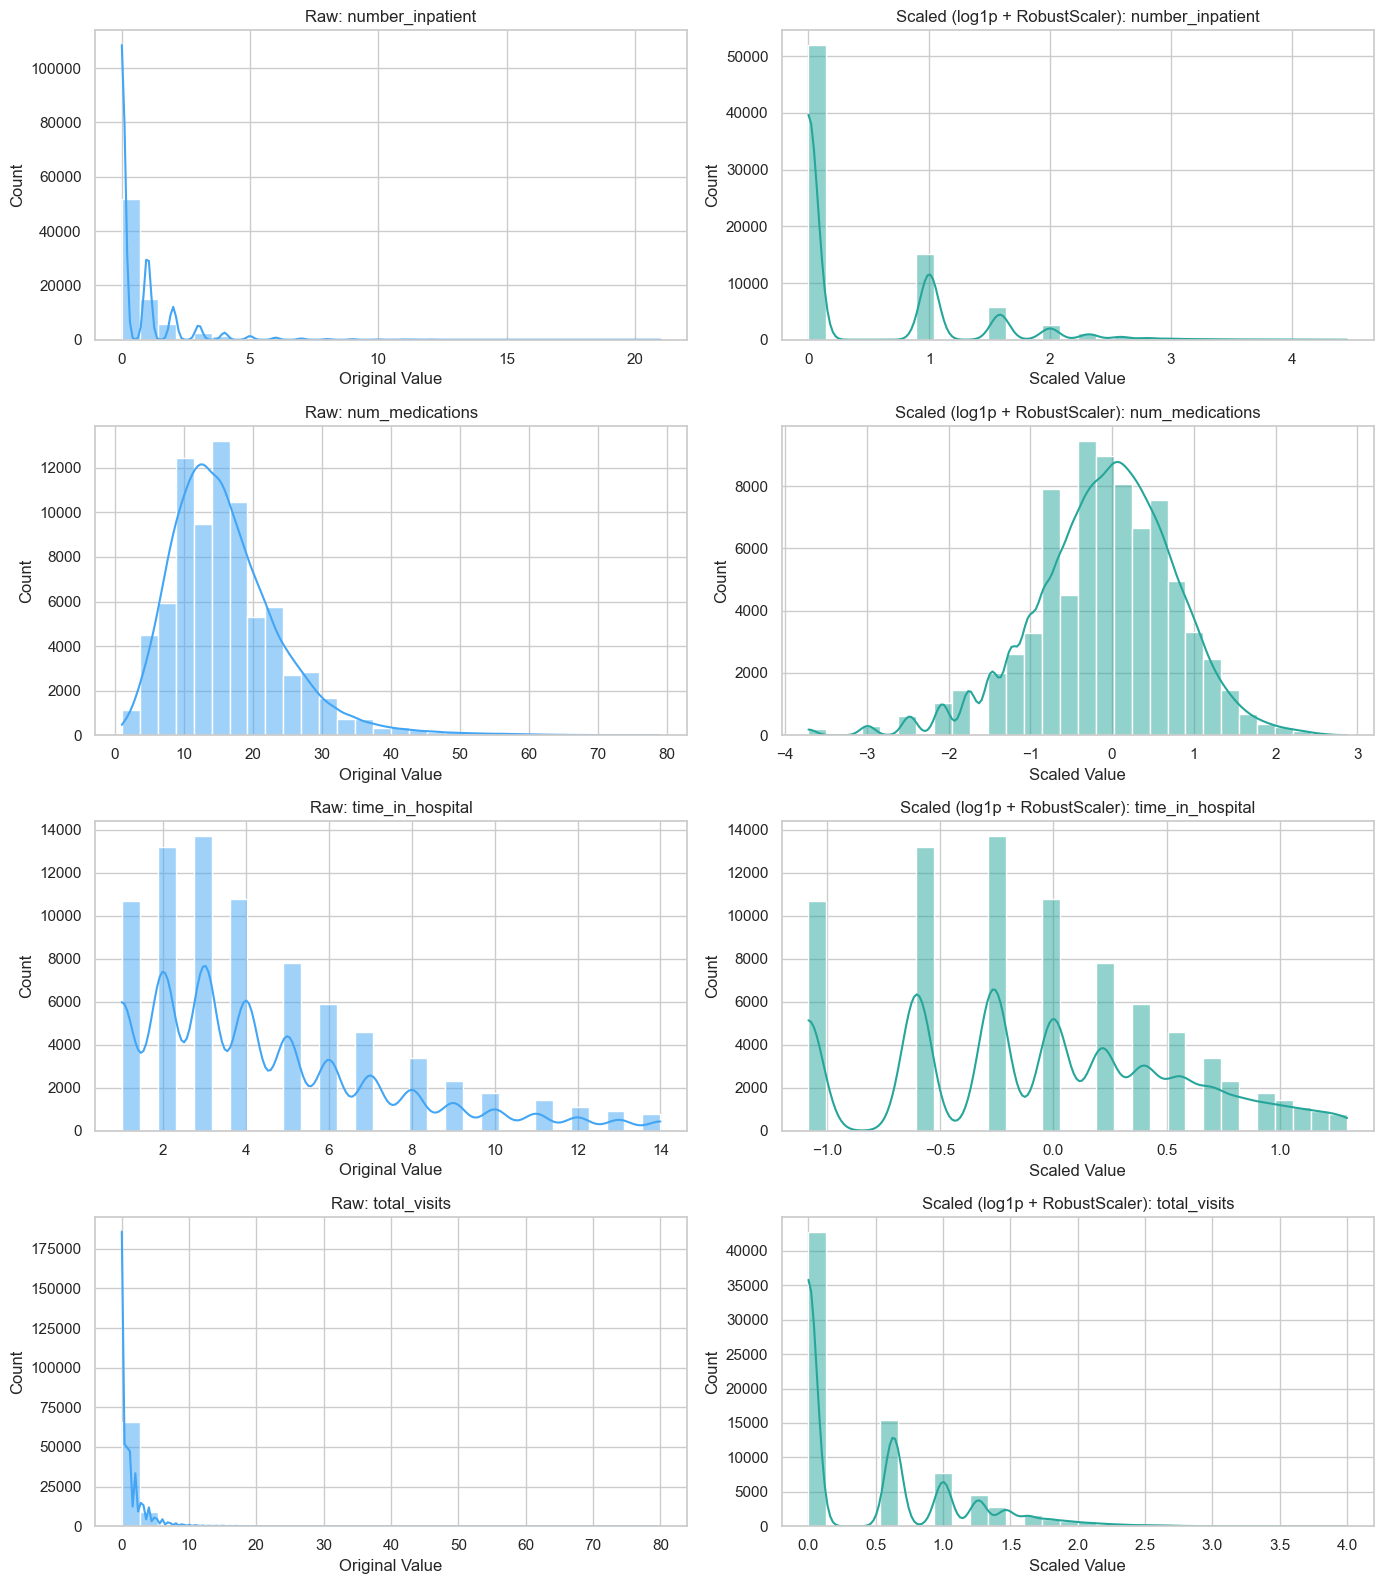

In [23]:
# Plot C: Raw vs Scaled distributions for key numeric features (read-only)
features_to_compare = ['number_inpatient', 'num_medications', 'time_in_hospital', 'total_visits']
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
for i, feat in enumerate(features_to_compare):
    # Raw (left)
    sns.histplot(X_train[feat], ax=axes[i, 0], kde=True, color='#42a5f5', bins=30)
    axes[i, 0].set_title(f'Raw: {feat}')
    axes[i, 0].set_xlabel('Original Value')
    # Scaled (right)
    sns.histplot(X_train_final[feat], ax=axes[i, 1], kde=True, color='#26a69a', bins=30)
    axes[i, 1].set_title(f'Scaled (log1p + RobustScaler): {feat}')
    axes[i, 1].set_xlabel('Scaled Value')
plt.tight_layout()
plt.savefig(f'{plots_dir}/Preprocessing/before_after_scaling.png', bbox_inches='tight')
plt.show()


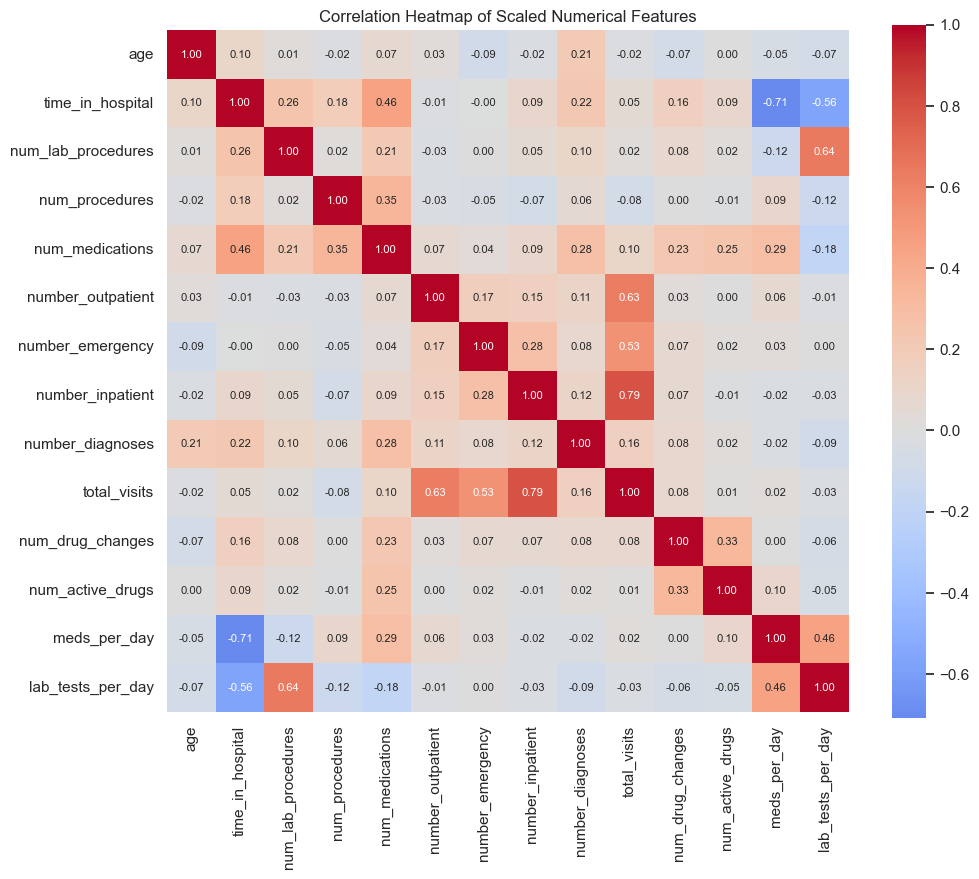

In [24]:
# Plot D: Correlation heatmap of processed numerical features (read-only)
corr = X_train_final[numerical_features].corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap='coolwarm', center=0, annot=True, fmt='.2f', square=True, annot_kws={'size': 8})
plt.title('Correlation Heatmap of Scaled Numerical Features')
plt.savefig(f'{plots_dir}/Preprocessing/correlation_heatmap.png', bbox_inches='tight')
plt.show()


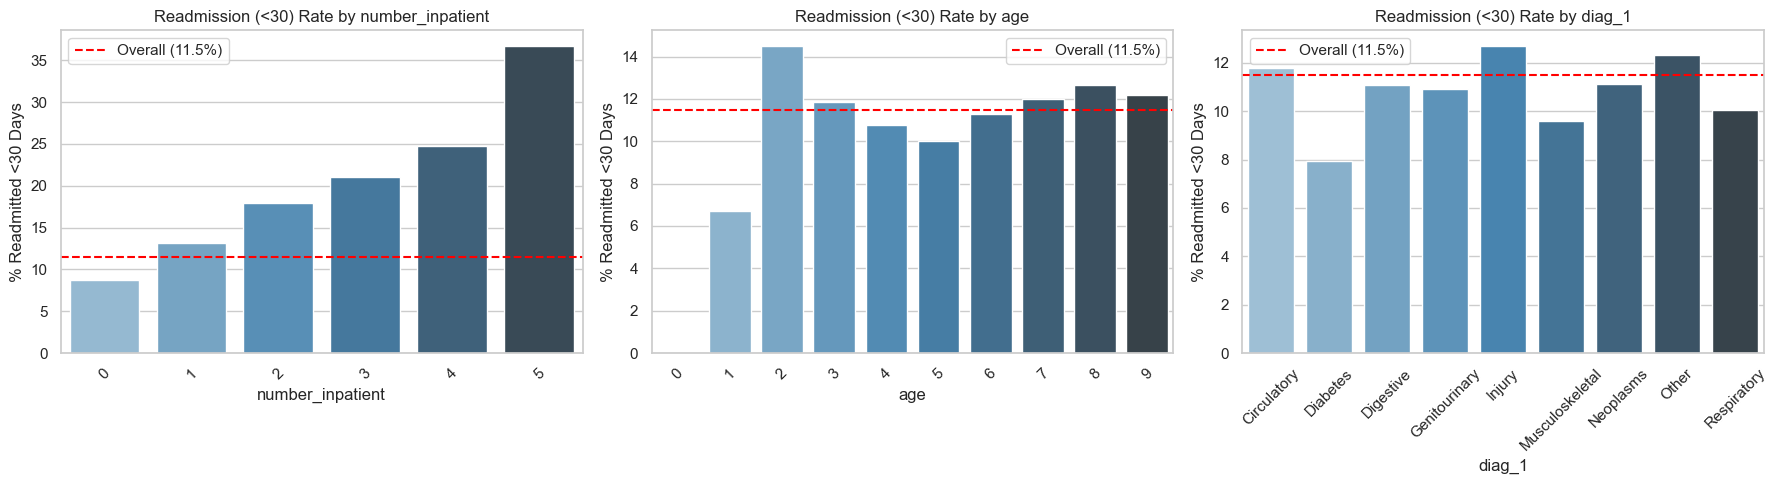

In [25]:
# Plot E: Readmission (<30) rate by key features (using train_df copy, read-only)
tmp = train_df.copy()
tmp['y'] = (tmp['readmitted'] == '<30').astype(int)
tmp['number_inpatient'] = tmp['number_inpatient'].clip(upper=5)
overall_rate = tmp['y'].mean() * 100

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plot_cols = ['number_inpatient', 'age', 'diag_1']
for ax, col in zip(axes, plot_cols):
    rates = tmp.groupby(col)['y'].mean() * 100
    sns.barplot(x=rates.index, y=rates.values, ax=ax, palette='Blues_d')
    ax.axhline(overall_rate, color='red', linestyle='--', linewidth=1.5, label=f'Overall ({overall_rate:.1f}%)')
    ax.set_title(f'Readmission (<30) Rate by {col}')
    ax.set_ylabel('% Readmitted <30 Days')
    ax.tick_params(axis='x', rotation=45)
    ax.legend()
plt.tight_layout()
plt.savefig(f'{plots_dir}/Preprocessing/readmission_rate_by_feature.png', bbox_inches='tight')
plt.show()


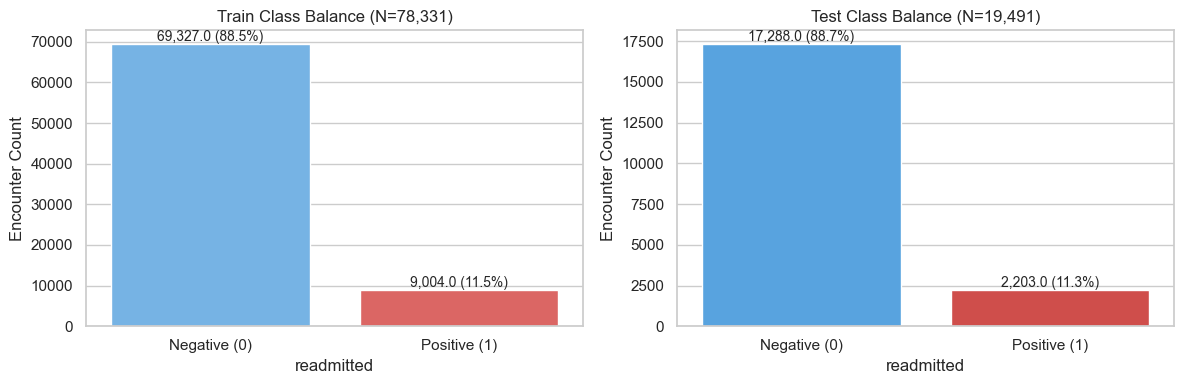

In [26]:
# Plot F: Final class balance bar chart for y_train and y_test side by side
train_counts = y_train.value_counts().rename({0: 'Negative (0)', 1: 'Positive (1)'})
test_counts  = y_test.value_counts().rename({0: 'Negative (0)', 1: 'Positive (1)'})

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x=train_counts.index, y=train_counts.values, ax=axes[0], palette=['#64b5f6', '#ef5350'])
for c_bar in axes[0].containers:
    axes[0].bar_label(c_bar, labels=[f'{v:,} ({v/len(y_train)*100:.1f}%)' for v in c_bar.datavalues], fontsize=10)
axes[0].set_title(f'Train Class Balance (N={len(y_train):,})')
axes[0].set_ylabel('Encounter Count')

sns.barplot(x=test_counts.index, y=test_counts.values, ax=axes[1], palette=['#42a5f5', '#e53935'])
for c_bar in axes[1].containers:
    axes[1].bar_label(c_bar, labels=[f'{v:,} ({v/len(y_test)*100:.1f}%)' for v in c_bar.datavalues], fontsize=10)
axes[1].set_title(f'Test Class Balance (N={len(y_test):,})')
axes[1].set_ylabel('Encounter Count')

plt.tight_layout()
plt.savefig(f'{plots_dir}/Preprocessing/final_class_balance.png', bbox_inches='tight')
plt.show()


In [27]:
# Print live class counts from y_train and y_test
print("=== Live Target Class Counts ===")
print(f"y_train: Negative (0) = {(y_train == 0).sum():,} ({(y_train == 0).mean()*100:.1f}%) | "
      f"Positive (1) = {(y_train == 1).sum():,} ({(y_train == 1).mean()*100:.1f}%) | "
      f"Total = {len(y_train):,}")
print(f"y_test:  Negative (0) = {(y_test == 0).sum():,} ({(y_test == 0).mean()*100:.1f}%) | "
      f"Positive (1) = {(y_test == 1).sum():,} ({(y_test == 1).mean()*100:.1f}%) | "
      f"Total = {len(y_test):,}")


=== Live Target Class Counts ===
y_train: Negative (0) = 69,327 (88.5%) | Positive (1) = 9,004 (11.5%) | Total = 78,331
y_test:  Negative (0) = 17,288 (88.7%) | Positive (1) = 2,203 (11.3%) | Total = 19,491


## Optional Phase 6A · Resampling Strategies for Class Imbalance (SMOTE / Oversampling / Undersampling)

> [!IMPORTANT]
> **CRITICAL DATA LEAKAGE PREVENTION RULE:**
> Resampling techniques (SMOTE, Random Oversampling, Undersampling) must **STRICTLY AND EXCLUSIVELY be applied to the training set (`X_train_final`, `y_train`)**.
> The test set (`X_test_final`, `y_test`) must **NEVER** be oversampled, undersampled, or modified in any way! The test set represents real-world clinical patient flow and must remain 100% natural and untouched to provide an unbiased evaluation.

### Comparison of Resampling Strategies & Trade-offs

| Strategy | Mechanism | Resampling Ratio | Clinical Impact & Trade-offs |
| :--- | :--- | :---: | :--- |
| **Baseline (No Resampling)** | Retains natural distribution; handles imbalance algorithmically via `class_weight='balanced'`. | Natural (~11.5% positive) | Preserves 100% genuine clinical data without synthetic artifacts or data deletion. |
| **Option A: SMOTE** | Synthesizes artificial minority vectors by interpolating between nearest neighbors. | `ratio=0.30` | Enhances minority representation; however, Euclidean interpolation can generate non-discrete values on one-hot encoded flags. |
| **Option B: RandomOverSampler** | Randomly duplicates existing positive instances with replacement. | `ratio=0.30` | Maintains valid discrete clinical values; slight risk of tree models overfitting repeated patterns. |
| **Option C: RandomUnderSampler** | Randomly discards majority (NO / >30) encounters to reduce imbalance. | `ratio=0.50` | Significantly accelerates training time; trade-off is discarding a large volume of historical clinical patterns. |
| **Option D: Combined (SMOTE + Under)** | Synthesizes minority up to 25%, then undersamples majority down to a 1:2 ratio. | Hybrid 1:2 ratio | Balanced hybrid: increases minority diversity while reducing majority dominance without extreme data loss. |

Below are optional, commented code blocks for each strategy using `imbalanced-learn`.
**How to use:** Uncomment the specific option you wish to experiment with before saving your final training matrices or fitting models.


In [28]:
# ==============================================================================
# OPTIONAL RESAMPLING STRATEGIES (UNCOMMENT TO EXPERIMENT)
# ==============================================================================
# NOTE: All resampling is applied STRICTLY to the training data (X_train_final, y_train)
# to prevent DATA LEAKAGE! The test set (X_test_final, y_test) remains 100% UNTOUCHED.

# print(f"Before resampling: X_train shape = {X_train_final.shape}")
# print("Class distribution before resampling:")
# print(y_train.value_counts(normalize=True) * 100)

# ------------------------------------------------------------------------------
# OPTION A: SMOTE (Synthetic Minority Over-sampling Technique)
# Synthesizes artificial minority records by interpolating between nearest neighbors.
# ------------------------------------------------------------------------------
# from imblearn.over_sampling import SMOTE
# smote = SMOTE(sampling_strategy=0.30, random_state=42)  # Adjust ratio as desired (e.g., 0.30)
# X_train_resampled, y_train_resampled = smote.fit_resample(X_train_final, y_train)
# print(f"After SMOTE: X_train shape = {X_train_resampled.shape}")
# print(y_train_resampled.value_counts(normalize=True) * 100)
# X_train_final, y_train = X_train_resampled, y_train_resampled

# ------------------------------------------------------------------------------
# OPTION B: RandomOverSampler (Duplicate Minority Samples)
# Randomly duplicates positive class (<30) instances with replacement.
# ------------------------------------------------------------------------------
# from imblearn.over_sampling import RandomOverSampler
# ros = RandomOverSampler(sampling_strategy=0.30, random_state=42)
# X_train_resampled, y_train_resampled = ros.fit_resample(X_train_final, y_train)
# print(f"After RandomOverSampler: X_train shape = {X_train_resampled.shape}")
# print(y_train_resampled.value_counts(normalize=True) * 100)
# X_train_final, y_train = X_train_resampled, y_train_resampled

# ------------------------------------------------------------------------------
# OPTION C: RandomUnderSampler (Downsample Majority Class)
# Randomly discards negative class instances to reduce imbalance ratio.
# ------------------------------------------------------------------------------
# from imblearn.under_sampling import RandomUnderSampler
# rus = RandomUnderSampler(sampling_strategy=0.50, random_state=42)
# X_train_resampled, y_train_resampled = rus.fit_resample(X_train_final, y_train)
# print(f"After RandomUnderSampler: X_train shape = {X_train_resampled.shape}")
# print(y_train_resampled.value_counts(normalize=True) * 100)
# X_train_final, y_train = X_train_resampled, y_train_resampled

# ------------------------------------------------------------------------------
# OPTION D: Combined (SMOTE + RandomUnderSampler)
# Synthesizes minority instances up to 25%, then undersamples majority to 50%
# ------------------------------------------------------------------------------
# from imblearn.pipeline import Pipeline as ImbPipeline
# from imblearn.over_sampling import SMOTE
# from imblearn.under_sampling import RandomUnderSampler
# resample_pipe = ImbPipeline([
#     ('smote', SMOTE(sampling_strategy=0.25, random_state=42)),
#     ('under', RandomUnderSampler(sampling_strategy=0.50, random_state=42))
# ])
# X_train_resampled, y_train_resampled = resample_pipe.fit_resample(X_train_final, y_train)
# print(f"After Combined Resampling: X_train shape = {X_train_resampled.shape}")
# print(y_train_resampled.value_counts(normalize=True) * 100)
# X_train_final, y_train = X_train_resampled, y_train_resampled

print("Resampling section loaded. Leave commented if using algorithmic weighting (class_weight='balanced').")
print("If you wish to test SMOTE, RandomOverSampler, or Undersampling, uncomment the chosen block above.")



Resampling section loaded. Leave commented if using algorithmic weighting (class_weight='balanced').
If you wish to test SMOTE, RandomOverSampler, or Undersampling, uncomment the chosen block above.


## Phase 6 · Save Outputs & Final Artifacts
We save all cleaned and validated feature matrices, targets, and the fitted Scikit-learn preprocessing pipeline for inference.


In [29]:
import joblib
import os

os.makedirs(processed_dir, exist_ok=True)

# Save final datasets
X_train_final.to_csv(f'{processed_dir}/X_train_final.csv', index=False)
X_test_final.to_csv(f'{processed_dir}/X_test_final.csv', index=False)
y_train.to_csv(f'{processed_dir}/y_train_final.csv', index=False)
y_test.to_csv(f'{processed_dir}/y_test_final.csv', index=False)

# Save the fitted pipeline for inference time
joblib.dump(preprocessor, f'{processed_dir}/preprocessing_pipeline.pkl')

print("All preprocessing artifacts saved successfully!")
print(f"  {processed_dir}/X_train_final.csv")
print(f"  {processed_dir}/X_test_final.csv")
print(f"  {processed_dir}/y_train_final.csv")
print(f"  {processed_dir}/y_test_final.csv")
print(f"  {processed_dir}/preprocessing_pipeline.pkl")
print(f"\nClass imbalance strategy: class_weight='balanced' will be applied in all model")
print(f"constructors to algorithmically handle the ~11% minority class (<30 days readmission).")
print(f"SMOTE will be explored during cross-validation experiments.")


All preprocessing artifacts saved successfully!
  dataset_processed/X_train_final.csv
  dataset_processed/X_test_final.csv
  dataset_processed/y_train_final.csv
  dataset_processed/y_test_final.csv
  dataset_processed/preprocessing_pipeline.pkl

Class imbalance strategy: class_weight='balanced' will be applied in all model
constructors to algorithmically handle the ~11% minority class (<30 days readmission).
SMOTE will be explored during cross-validation experiments.


**Binary Imbalance Strategy:** Positive class (`<30`) constitutes ~11.5% of total encounters, while the combined Negative class (`NO` + `>30`) constitutes ~88.5%. We recommend using `class_weight='balanced'` or `scale_pos_weight` in tree algorithms (LightGBM/XGBoost) rather than random downsampling, which would discard valuable patient history. Primary evaluation metrics should be **Recall**, **F1-Score on the Positive Class**, and **PR-AUC / ROC-AUC**.


# 🏁 Preprocessing & Feature Engineering Handoff Summary
**For the Modeling Team:** The data is now fully cleaned, encoded, and ready for modeling. Here is everything you need to know about what was done and why.

### 1. Final Datasets (`dataset_processed/`)
- `X_train_final.csv` / `y_train_final.csv`
- `X_test_final.csv` / `y_test_final.csv`
- **Shapes:** The final matrices contain precisely aligned 86 features with 0 missing values.
- **Preprocessing Pipeline:** `preprocessing_pipeline.pkl` contains the fitted `ColumnTransformer`. If you need to transform new unseen data, call `.transform(new_data)`.

### 2. Splitting Strategy
- **Patient-Level Split:** We did NOT use a random split. We grouped by `patient_nbr` and placed all encounters for a single patient into either train or test. This prevents **patient memorization leakage**.

### 3. Removed Features (And Why)
- `weight`: Dropped (97% missing — imputing creates pure bias).
- `patient_nbr`, `encounter_id`: Dropped (pure identifiers — causes leakage).
- `_desc` columns: Dropped (redundant exact text equivalents of the `_id` columns).
- `chlorpropamide` & 20 other drugs: Dropped (near-zero variance; >99% of patients did not take them).
- **Raw Drug Columns:** Dropped after extracting their signal into the `num_drug_changes` and `num_active_drugs` summaries to prevent severe multicollinearity.

### 4. Selected / Engineered Features
- `total_visits`: Sum of past inpatient, outpatient, and emergency visits (strong proxy for a 'high-utilizer' patient).
- `meds_per_day` / `lab_tests_per_day`: Removed the confound of length of stay by creating intensity ratios.
- **Grouped ICD-9 Codes:** Mapped 700+ raw `diag` codes into 9 clinical categories (e.g., 'Diabetes', 'Circulatory') for stability.
- **Grouped Admin Codes:** Mapped ID numbers into semantic categories (e.g., 'Home', 'Facility', 'Emergency').

### 5. Encoding & Scaling
- **Numerical:** Handled outliers via `log1p` transformation (compresses the extreme right tail of high-utilizers without dropping them) + `RobustScaler`.
- **Categorical:** Nominal features use OneHotEncoder; binary/ordered features (gender, change, diabetesMed, max_glu_serum, A1Cresult, insulin) use OrdinalEncoder.
- **Age:** Explicitly ordinalized (`[0-10) -> 0`, etc.) and passed through the numeric pipeline.

### 6. Next Steps for Modeling
- **Algorithmic Feature Selection:** We have removed redundant and leaky features. If you want to reduce dimensionality further, apply algorithmic selection (e.g., Lasso L1 penalty, Random Forest feature importance, SelectKBest) as part of your tuning pipeline.
- **Class Imbalance:** The `<30` target class is only ~11.5%. Use `class_weight='balanced'` in your model constructors (LogisticRegression, RandomForest, etc.) or apply SMOTE to the training set. Evaluate using **Recall** and **Macro F1**.


## 💡 Future Pipeline Suggestions & Methodological Observations (Unapplied)

The following items represent potential refinements identified during code review. To strictly preserve historical benchmark results and cross-team consistency, they are intentionally **unapplied** in this version:

1. **ICD-9 Decimal Truncation in `map_diagnosis`:** The current grouper evaluates `c == 250`, `c == 785`, etc. Under this exact float comparison, subcodes with decimal clinical specifications (such as `250.01` for type 1 diabetes or `786.5` for chest pain) fall into the `'Other'` bucket. In future iterations, expanding conditions to range intervals (e.g., `250 <= c < 251`, `785 <= c < 786`) would capture thousands of secondary diabetes cases currently mapped to `'Other'`.
2. **Missing Secondary Diagnoses (`diag_2` / `diag_3`):** Step 3f currently drops encounters missing secondary or tertiary diagnoses. In medical informatics, a missing secondary diagnosis frequently signals an uncomplicated, single-condition hospital encounter rather than missing data. Imputing secondary diagnoses as `'None'` or `'Not applicable'` would preserve ~1,500 additional patient records.
3. **IQR Upper Fence Bounds on Zero-Inflated Counts:** For sparse prior utilization counts like `number_outpatient` and `number_emergency`, the 75th percentile is 0, making the calculated upper fence $0 + 1.5 \times 0 = 0$. Consequently, any patient with even 1 prior visit is flagged as an 'outlier'. While statistically expected for zero-inflated distributions, percentage thresholds or quantile flags provide a more clinically intuitive summary.
4. **Monotonicity in Insulin Ordering:** Mapping insulin as `No < Down < Steady < Up` imposes a monotonic ordinal assumption. However, clinical literature and EDA show that dosage reduction (`Down`) can indicate acute hypoglycemia or severe disease volatility, presenting a non-linear risk profile distinct from dosage escalation (`Up`).
